# Mecanismo de dos lazos acoplados con actuadores en `theta1` y `theta4`: cinemática y animación de la pata

Mecanismo plano de barras con **dos actuadores** (`theta1` y `theta4`, uno en cada primer eslabón) y tres lazos cerrados. Dado el movimiento de los dos actuadores se resuelven por cinemática inversa los ángulos pasivos (`theta2`, `theta3`, `theta5`, `theta6`, `theta7`) y la longitud variable `d` de la barra `DG`.

El notebook hace:

1. Plantea el **modelo simbólico**: marcos de referencia, vectores de los eslabones y las ecuaciones de cierre de los 3 lazos con sympy.
2. Define los **parámetros** (longitudes, posición del pivote, límite de `d`) y la trayectoria de los dos actuadores.
3. Resuelve las 6 ecuaciones no lineales con `fsolve` en cada paso de la trayectoria.
4. Grafica todos los ángulos y la longitud `d`, y **anima** el mecanismo completo.

## Contenido

| Sección | Qué hace |
|---|---|
| 1. Imports | Librerías |
| 2. Modelo simbólico | Marcos, vectores y ecuaciones de cierre de lazo con sympy |
| 3. Parámetros y trayectoria | Longitudes, pivote, límite de `d` y ángulos de los actuadores |
| 4. Cinemática inversa | Resolución de los lazos con `fsolve` en cada paso |
| 5. Gráficas | Ángulos y longitud `d` a lo largo de la trayectoria |
| 6. Puntos del mecanismo | Posición de las articulaciones en cada paso |
| 7. Animación | Animación del mecanismo completo |

## Convenciones

- Plano x-y, ángulos positivos en sentido antihorario, 0 = eje +x. Los marcos `A` a `G` se obtienen girando `N` (o `C`, `D`) alrededor de `z`, igual que `orientnew` en sympy.
- Los **actuadores** son `theta1` y `theta4`; el resto de los ángulos (`theta2`, `theta3`, `theta5`, `theta6`, `theta7`) y `d` son incógnitas pasivas.
- Longitudes en metros, ángulos en radianes (las gráficas y la animación los muestran en grados y mm).
- Los puntos del mecanismo son `O`, `A`, `B`, `C`, `D`, `E`, `F`, `G` y las barras `OA`, `AB`, `CF`, `CD`, `DE`, `FG`, `DG` (esta última de longitud variable `d`, punteada en la animación).

## 1. Imports

Sympy para el modelo simbólico, NumPy para los cálculos, SciPy (`fsolve`) para resolver las ecuaciones y Matplotlib para las gráficas y la animación.

In [1]:
import sympy as sp
from sympy.physics.mechanics import dynamicsymbols, ReferenceFrame
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import fsolve
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

## 2. Modelo simbólico

Define los símbolos, los marcos de referencia, los vectores de los eslabones y las **ecuaciones de cierre de lazo**:

- `loop1`: pivote + `r1` + `r2` + `r3` (lazo `OAB` con el pivote `p1x`, `p1y`).
- `loop2`: `r4` + `r5` + `r6` + `r8` (lazo `DEF` con la barra `C`).
- `loop3`: `r4` + `r7` + `r9` + `r8` (lazo con la barra de longitud variable `d`).

`eq` son las 6 ecuaciones escalares (x e y de cada lazo), que `lambdify` convierte en la función numérica `fun_eq`. Las incógnitas son `theta2`, `theta3`, `theta5`, `theta6`, `theta7` y `d`; `theta1` y `theta4` entran como parámetros porque son los actuadores.

In [2]:
theta1, theta2, theta3, theta4, theta5, theta6, theta7, d = dynamicsymbols('theta1 theta2 theta3 theta4 theta5 theta6 theta7 d')
l1, l2, l3, l4, l5, l6, l8, l9, p1x, p1y, t = sp.symbols('l1 l2 l3 l4 l5 l6 l8 l9 p1x p1y t')

# Ejes de referencia

N = ReferenceFrame('N')
A = N.orientnew('A', 'Axis', (N.z, theta1))
B = N.orientnew('B', 'Axis', (N.z, -theta2))
C = N.orientnew('C', 'Axis', (N.z, theta3))
D = N.orientnew('D', 'Axis', (N.z, -theta4))
E = D.orientnew('E', 'Axis', (N.z, theta5))
F = C.orientnew('F', 'Axis', (N.z, -theta6))
G = N.orientnew('G', 'Axis', (N.z, theta7))

# Pivotes

pvt_1 = p1x*N.x + p1y*N.y

# Vectores

r1 = l1*A.x
r2 = l2*B.x
r3 = -l3*C.x
r4 = l4*D.x
r5 = l5*E.x
r6 = -l6*F.x
r7 = d*G.x
r8 = -l8*C.x
r9 = -l9*F.x

# Loop

loop1 = pvt_1 + r1 + r2 + r3
loop2 = r4 + r5 + r6 + r8
loop3 = r4 + r7 + r9 + r8

# Ecuaciones

eqx1 = loop1.dot(N.x)
eqy1 = loop1.dot(N.y)

eqx2 = loop2.dot(N.x)
eqy2 = loop2.dot(N.y)

eqx3 = loop3.dot(N.x)
eqy3 = loop3.dot(N.y)

eq = [eqx1, eqy1, eqx2, eqy2, eqx3, eqy3]

fun_eq = sp.lambdify((theta2, theta3, theta5, theta6, theta7, d, theta1, theta4, l1, l2, l3, l4, l5, l6, l8, l9, p1x, p1y), eq, "numpy")

## 3. Parámetros y trayectoria

### 3.1 Valores del mecanismo

| Parámetro | Significado |
|---|---|
| `val` | Longitudes `l1` a `l9` [m] y posición del pivote `p1x`, `p1y` [m] |
| `d_min` | Longitud mínima admisible de `d` [m]; los pasos que la incumplen se descartan |
| `tau_motor1`, `tau_motor2` | Par de los motores de los dos actuadores |

Todos se pueden editar.

In [3]:
# Valores

val = {l1: 0.020, l2: 0.03124, l3: 0.020, l4: 0.020,
       l5: 0.070, l6: 0.020, l8: 0.070, l9: 0.100,
       p1x: 0.024, p1y: -0.020}

d_min = 0.020

tau_motor1 = 2.2
tau_motor2 = 2.2

### 3.2 Trayectoria de los actuadores

`theta1` y `theta4` oscilan sinusoidalmente (60 pasos por ciclo): `theta1` en 45° ± 15° con seno y `theta4` en -145° ± 15° con coseno. Ambos son entradas del problema.

In [4]:
ang = np.linspace(0, 2*np.pi, 60, endpoint=False)
theta1_val = np.radians(45) + np.radians(15)*np.sin(ang)
theta4_val = np.radians(-145) + np.radians(15)*np.cos(ang)

## 4. Cinemática inversa

Para cada par (`theta1`, `theta4`) se resuelven las 6 ecuaciones de cierre de lazo con `fsolve`, usando como estimación inicial la solución del paso anterior (la primera es `estimacion_angulos`). Si la solución tiene `d < d_min` el paso se descarta. Los resultados se guardan en las listas `*_sol`.

In [5]:
estimacion_angulos = [np.radians(-140), np.radians(45), np.radians(-85), np.radians(-85), np.radians(91), 0.111]
theta1_sol = []
theta4_sol = []
theta2_sol = []
theta3_sol = []
theta5_sol = []
theta6_sol = []
theta7_sol = []
d_sol = []

for theta1n, theta4n in zip(theta1_val, theta4_val):
      regleta = lambda v: fun_eq(*v, theta1n, theta4n, val[l1], val[l2], val[l3], val[l4], val[l5], val[l6], val[l8], val[l9], val[p1x], val[p1y])
      solu = fsolve(regleta, estimacion_angulos)
      estimacion_angulos = solu
      if solu[5] < d_min:
            continue
      theta1_sol.append(theta1n)
      theta4_sol.append(theta4n)
      theta2_sol.append(solu[0])
      theta3_sol.append(solu[1])
      theta5_sol.append(solu[2])
      theta6_sol.append(solu[3])
      theta7_sol.append(solu[4])
      d_sol.append(solu[5])

## 5. Gráficas

Ángulos de los 7 eslabones (en grados) y longitud `d` de la barra `DG` (en mm) a lo largo de la trayectoria.

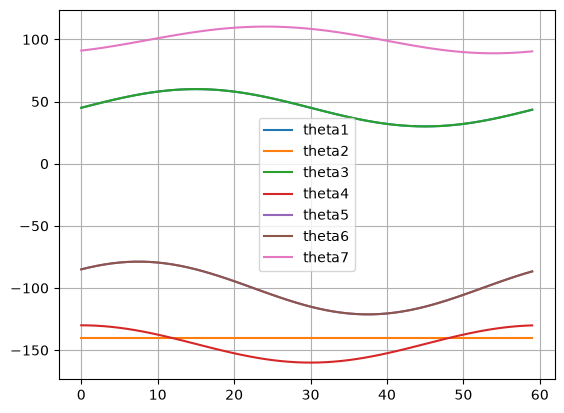

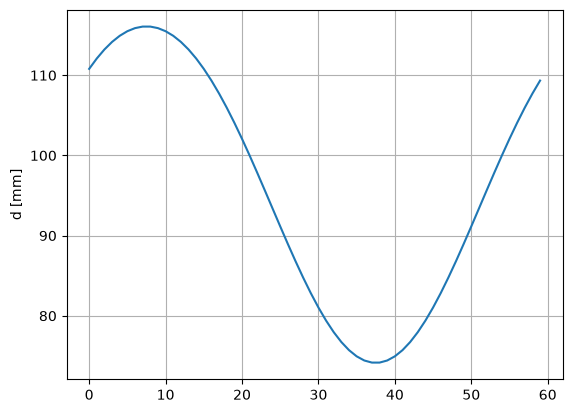

In [6]:
plt.figure()
plt.plot(np.degrees(theta1_sol), label='theta1')
plt.plot(np.degrees(theta2_sol), label='theta2')
plt.plot(np.degrees(theta3_sol), label='theta3')
plt.plot(np.degrees(theta4_sol), label='theta4')
plt.plot(np.degrees(theta5_sol), label='theta5')
plt.plot(np.degrees(theta6_sol), label='theta6')
plt.plot(np.degrees(theta7_sol), label='theta7')
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.plot(np.array(d_sol)*1000)
plt.ylabel('d [mm]')
plt.grid()
plt.show()

## 6. Puntos del mecanismo

Posiciones de las articulaciones `O`, `A`, `B`, `C`, `D`, `E`, `F`, `G` en cada paso, sumando los vectores de los eslabones ya resueltos. `evaluar_vector` sustituye los valores numéricos en un vector de sympy y devuelve sus componentes x e y; `puntos_animacion` guarda las 8 posiciones de cada paso.

Barras: `OA`, `AB`, `CF`, `CD`, `DE`, `FG` y `DG`.

In [7]:
#Puntos

pO = (0, 0)
pA = r1
pB = r1 + r2
pC = r1 + r2 + r3
pD = pC + r4
pE = pD + r5
pF = pE + r6
pG = pD + r7


def evaluar_vector(vector, valores):
    return np.array([
        float(vector.dot(N.x).subs(valores)),
        float(vector.dot(N.y).subs(valores))
    ])

puntos_animacion = []

for i in range(len(theta1_sol)):

    valores = {
        **val,
        theta1: theta1_sol[i],
        theta2: theta2_sol[i],
        theta3: theta3_sol[i],
        theta4: theta4_sol[i],
        theta5: theta5_sol[i],
        theta6: theta6_sol[i],
        theta7: theta7_sol[i],
        d: d_sol[i]
    }

    R1 = evaluar_vector(r1, valores)
    R2 = evaluar_vector(r2, valores)
    R3 = evaluar_vector(r3, valores)
    R4 = evaluar_vector(r4, valores)
    R5 = evaluar_vector(r5, valores)
    R6 = evaluar_vector(r6, valores)
    R7 = evaluar_vector(r7, valores)

    PO = np.array([0.0, 0.0])
    PA = PO + R1
    PB = PA + R2
    PC = PB + R3
    PD = PC + R4
    PE = PD + R5
    PF = PE + R6
    PG = PD + R7

    puntos_animacion.append(
        np.array([PO, PA, PB, PC, PD, PE, PF, PG])
    )

puntos_animacion = np.array(puntos_animacion)

## 7. Animación

Animación del mecanismo completo siguiendo la trayectoria, con los nombres de los puntos y los valores de `theta1`, `theta4` y `d` en cada cuadro. La barra `DG` (longitud variable) se dibuja punteada. Toda la animación se gira 90° (antihorario) alrededor de `O` con `giro`; es solo visual, no cambia la cinemática.

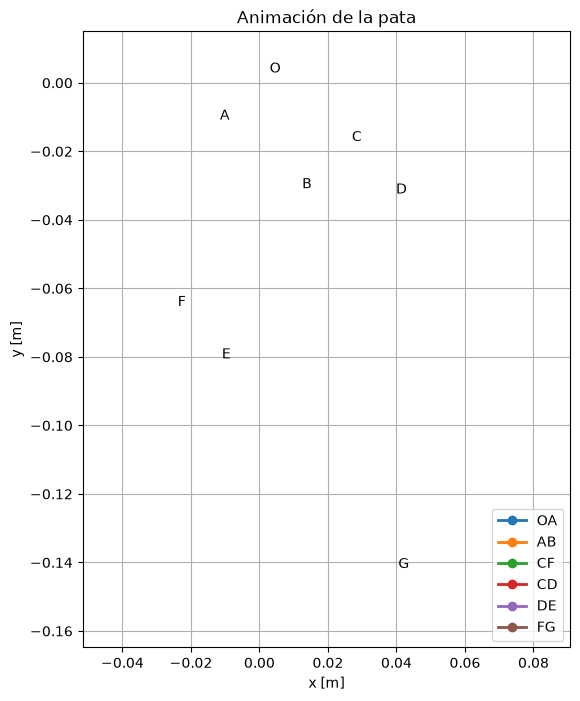

In [8]:
# Giro de toda la animacion (antihorario, alrededor de O)
giro = np.radians(180)
R_giro = np.array([[np.cos(giro), -np.sin(giro)],
                   [np.sin(giro),  np.cos(giro)]])
puntos_animacion = puntos_animacion @ R_giro.T

fig, ax = plt.subplots(figsize=(9, 8))

xmin = puntos_animacion[:, :, 0].min()
xmax = puntos_animacion[:, :, 0].max()
ymin = puntos_animacion[:, :, 1].min()
ymax = puntos_animacion[:, :, 1].max()

margen = 0.1 * max(xmax - xmin, ymax - ymin)

ax.set_xlim(xmin - margen, xmax + margen)
ax.set_ylim(ymin - margen, ymax + margen)
ax.set_aspect('equal', adjustable='box')
ax.grid(True)
ax.set_xlabel('x [m]')
ax.set_ylabel('y [m]')
ax.set_title('Animación de la pata')

nombres_puntos = ['O', 'A', 'B', 'C', 'D', 'E', 'F', 'G']
indice = {nombre: j for j, nombre in enumerate(nombres_puntos)}

uniones = [('O', 'A'), ('A', 'B'), ('C', 'F'), ('C', 'D'), ('D', 'E'), ('F', 'G')]

barras = []
for p, q in uniones:
    estilo = 'o--' if (p, q) == ('D', 'G') else 'o-'
    barras.append(ax.plot([], [], estilo, lw=2, label=p + q)[0])

etiquetas = [
    ax.text(0, 0, nombre, fontsize=10)
    for nombre in nombres_puntos
]

texto_angulo = ax.text(
    0.02, 0.98, '',
    transform=ax.transAxes,
    va='top'
)

ax.legend(loc='lower right')

def init():
    for barra in barras:
        barra.set_data([], [])

    texto_angulo.set_text('')
    return barras + etiquetas + [texto_angulo]


def update(i):
    pts = puntos_animacion[i]

    for barra, (p, q) in zip(barras, uniones):
        barra.set_data(
            [pts[indice[p], 0], pts[indice[q], 0]],
            [pts[indice[p], 1], pts[indice[q], 1]]
        )

    for j, etiqueta in enumerate(etiquetas):
        etiqueta.set_position(pts[j] + np.array([0.003, 0.003]))

    texto_angulo.set_text(
        f'theta1 = {np.degrees(theta1_sol[i]):.1f}°\n'
        f'theta4 = {np.degrees(theta4_sol[i]):.1f}°\n'
        f'd = {d_sol[i]*1000:.1f} mm'
    )

    return barras + etiquetas + [texto_angulo]


ani = FuncAnimation(
    fig,
    update,
    frames=len(theta1_sol),
    init_func=init,
    interval=100,
    blit=False,
    repeat=True
)

display(HTML(ani.to_jshtml()))